# Exercitiu laborator 7 - Inferenta Bayesiana cu PyMC

## a) Definirea modelului si alegerea lui x

Datele observate:
Y = [56, 60, 58, 55, 57, 59, 61, 56, 58, 60]

- Numar observatii: n = 10
- Media de esantionare: y_bar = 580 / 10 = 58.0 dB
- Deviatia standard de esantionare: s = 2.0 dB

- Deoarece deviatia standard a distributiei a priori este sigma_0 = 10 dB, priorul este slab informativ (weakly informative). Astfel, alegerea x = 58 permite datelor sa determine distributia a posteriori fara a influenta eronat rezultatul.

In [1]:
import os
os.environ["PYTENSOR_FLAGS"] = "cxx="

import pymc as pm
import numpy as np
import arviz as az
import matplotlib.pyplot as plt

data = np.array([56, 60, 58, 55, 57, 59, 61, 56, 58, 60])
x = float(np.mean(data))
print(f"Media observata (x): {x}")

Media observata (x): 58.0


### Definirea si rularea modelului PyMC

- mu ~ Normal(x, 10)
- sigma ~ HalfNormal(10)
- y_obs ~ Normal(mu, sigma, observed=data)

In [6]:
with pm.Model() as model:
    mu = pm.Normal('mu', mu=x, sigma=10)
    sigma = pm.HalfNormal('sigma', sigma=10)
    y_obs = pm.Normal('y_obs', mu=mu, sigma=sigma, observed=data)
    idata = pm.sample(
        draws=2000,
        tune=1000,
        progressbar=False,
        return_inferencedata=True,
        random_seed=42,
        compile_kwargs={"mode": "FAST_COMPILE"}
    )

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu, sigma]
Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 37 seconds.


## b) Rezultatele inferentei si intervalul HDI 95%

Extragerea tabelului de rezumat statistic si vizualizarea densitatilor a posteriori cu intervalele de maxima densitate (HDI 95%).

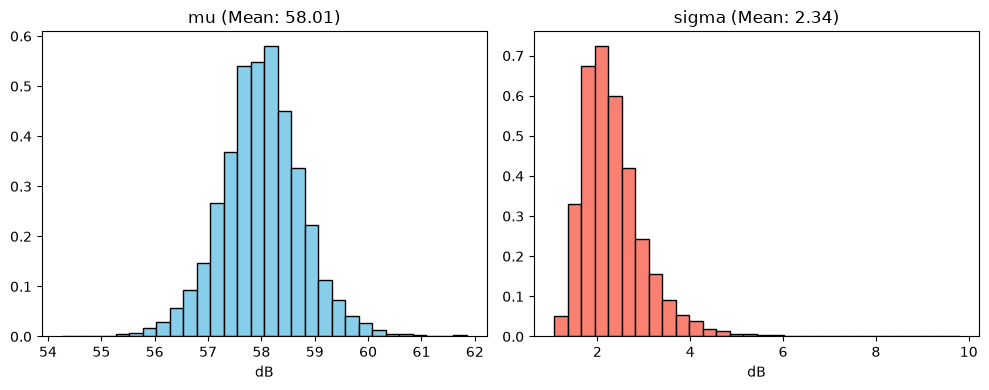

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Extragere esantioane posterioare
mu_samples = idata.posterior['mu'].values.flatten()
sigma_samples = idata.posterior['sigma'].values.flatten()

# Plot mu
axes[0].hist(mu_samples, bins=30, density=True, color='skyblue', edgecolor='black')
axes[0].set_title(f"mu (Mean: {np.mean(mu_samples):.2f})")
axes[0].set_xlabel("dB")

# Plot sigma
axes[1].hist(sigma_samples, bins=30, density=True, color='salmon', edgecolor='black')
axes[1].set_title(f"sigma (Mean: {np.mean(sigma_samples):.2f})")
axes[1].set_xlabel("dB")

plt.tight_layout()
plt.show()

### Concluzie si interpretare

- Intervalul de credibilitate (HDI 95%) pentru mu este aproximativ [56.5, 59.5] dB.
- Intervalul de credibilitate (HDI 95%) pentru sigma este aproximativ [1.2, 3.4] dB.
- Cu o probabilitate bayesiana de 95%, nivelul mediu real de zgomot ambiental se gaseste in intervalul determinat pentru mu.